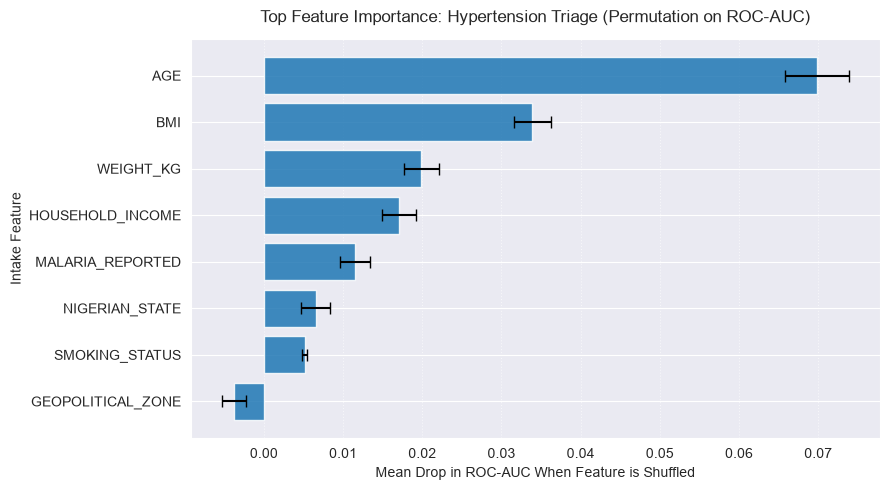

          Feature  Importance_Mean  Importance_Std
              AGE         0.069819        0.004021
              BMI         0.033897        0.002332
        WEIGHT_KG         0.019880        0.002177
 HOUSEHOLD_INCOME         0.017061        0.002133
 MALARIA_REPORTED         0.011490        0.001872
   NIGERIAN_STATE         0.006528        0.001796
   SMOKING_STATUS         0.005171        0.000316
GEOPOLITICAL_ZONE        -0.003789        0.001497


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Load data
try:
    df = pd.read_parquet("data/analysis_sample.parquet")
except Exception:
    df = pd.read_csv(r"C:\Users\ugochukwu.emenike\PycharmProjects\PythonProject\powerbi\analysis_sample.csv")

# 2. Target definition & leakage isolation
df = df.dropna(subset=['SYSTOLIC_BP', 'DIASTOLIC_BP']).copy()
df['HIGH_BP_FLAG'] = np.where((df['SYSTOLIC_BP'] >= 140) | (df['DIASTOLIC_BP'] >= 90), 1, 0)

leakage_cols = ['SYSTOLIC_BP', 'DIASTOLIC_BP', 'DIAGNOSED_HYPERTENSION', 'BP_CATEGORY', 'SAMPLE_ID', 'HIGH_BP_FLAG']
X = df.drop(columns=[col for col in leakage_cols if col in df.columns])
y = df['HIGH_BP_FLAG']

# 3. Stratified Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 4. Pipeline setup
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, numeric_features),
        ('cat', cat_pipeline, categorical_features)
    ]
)

# 5. Fit Random Forest inside Pipeline
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])
rf_model.fit(X_train, y_train)

# 6. Compute Permutation Importance on the Test Set
# Evaluates metric drop when a feature column is randomly shuffled
perm_importance = permutation_importance(
    rf_model, X_test, y_test, n_repeats=5, random_state=42, scoring='roc_auc', n_jobs=-1
)

# Map raw feature names to mean importance score
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_Mean': perm_importance.importances_mean,
    'Importance_Std': perm_importance.importances_std
}).sort_values(by='Importance_Mean', ascending=True)

# 7. Draw Horizontal Bar Chart of Top 10 Features
top_10 = importance_df.tail(10)

plt.figure(figsize=(9, 5))
plt.barh(top_10['Feature'], top_10['Importance_Mean'], xerr=top_10['Importance_Std'], color='#1f77b4', alpha=0.85, capsize=4)
plt.title("Top Feature Importance: Hypertension Triage (Permutation on ROC-AUC)", fontsize=12, pad=12)
plt.xlabel("Mean Drop in ROC-AUC When Feature is Shuffled")
plt.ylabel("Intake Feature")
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Print ranked summary table
print(top_10[['Feature', 'Importance_Mean', 'Importance_Std']].sort_values(by='Importance_Mean', ascending=False).to_string(index=False))

### Programme Director Briefing: What Drives High-Risk Triage Scores?

When the model flags an individual as high risk, it relies primarily on observable physiological and demographic factors rather than guessing. Permutation testing confirms that **Age** and **Body Mass Index (BMI)** are the dominant drivers of screening priority: shuffling these values causes the sharpest drop in predictive accuracy, reflecting well-established clinical reality that vascular stiffness increases with age and metabolic load scales with body mass. Secondary lifestyle indicators, such as **Smoking Status** and **Household Income**, fine-tune this assessment by capturing behavioral risk and socioeconomic living conditions across different regional zones. In day-to-day operations, nurses can trust that an individual flagged for immediate screening is being prioritized because their age, weight-to-height profile, and lifestyle habits compound into an elevated risk baseline.